# T-phi: cuts and fixed-T coils (TPHI3D_edge)

This notebook follows `examples/ring_3D_tphi` and `examples/coil_core_3D_tphi`. In the T-phi formulation

$$\mathbf{H}=\mathbf{T}-\nabla\phi,\qquad \mathbf{J}=\nabla\times\mathbf{T},$$

$\phi$ (`PHI`, nodal) lives everywhere and $\mathbf{T}$ (`T`, edge elements) only in the conductors and in
`CUT_LAYER` cells. There is no source current and no circuit: currents are carried by $\mathbf{T}$. It shows:

1. **why a cut** is needed for a conductor with a net current, and how to build one (a ring);
2. the three **drives** of a cut: an induced current, an imposed current, an imposed voltage, and their consistency
   (the same resistance and time constant);
3. what happens **without the cut**;
4. a current-driven **coil as T fixed on its edges** around a conducting core.

See the user manual (*Element library: TPHI3D_edge* and *Cuts*) and the theory (*Scalar potentials*).

In [1]:
import contextlib, io, os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection, tree_gauge
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # the job log keeps everything (<model>.log in the working folder)
MU0 = 4e-7 * np.pi
QUIET = {"-ksp_monitor": None, "-ksp_view": None, "-ksp_converged_reason": None, "-log_view": None,
         "-ksp_monitor_true_residual": None, "-ksp_monitor_solution": None}   # no PETSc reports in the notebook

EXAMPLES = Path("../../examples").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_tphi_"))
for case in ("ring_3D_tphi", "coil_core_3D_tphi"):
    folder = EXAMPLES / case
    for f in (case + ".vtu", "model_data.json"):
        shutil.copy(folder / f, WORK / f"{case}_{f}" if f == "model_data.json" else WORK / f)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

def quietly():
    """Keep the report tables of the solver (and libMesh's Newton trace) out of the notebook: they are in the job log."""
    return contextlib.redirect_stdout(io.StringIO())

def new_solver(case, log):
    """A solver on the example's mesh and model data (model_data.json copied as <case>_model_data.json)."""
    solver = Solver(log_file=log)
    solver.read_model(case + ".vtu")
    solver.model.read_json(case + "_model_data.json")
    solver.solver_settings = {"petsc_options": QUIET}
    return solver

def select_surface(grid, conductor, others, midside):
    """Select the points shared by the cells of TYPE ``conductor`` and those of TYPEs ``others`` (the surface of the
    conductor): its midside points (midside=True: the edge DOFs) or its corner points."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="r")
    selection.select(grid, "MidsideNodes", int(midside), mode="r")

def select_inside(grid, conductor, others):
    """Select the corner points of the cells of TYPE ``conductor`` that no cell of TYPEs ``others`` has."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="u")
    selection.select(grid, "MidsideNodes", 0, mode="r")

working in a temporary folder: pytec3d_tphi_5l526yyk


## Why a cut

Outside the conductors $\mathbf{H}=-\nabla\phi$ with a single-valued $\phi$: its circulation along any closed loop is
zero. A loop around a ring carrying the current I must give I (Ampère): the air must be made simply connected by a
**cut**, a surface spanning the hole on which $\mathbf{T}$ carries the jump. In practice: a one-cell layer of
`CUT_LAYER` cells on one side of the surface, with $\mathbf{T}=I\nabla c$, c going from 0 to 1 across the layer:

* the edges in the two faces of the layer (*planar*) have $\int\mathbf{T}\cdot d\mathbf{l}=0$;
* the edges *crossing* the layer have $\int\mathbf{T}\cdot d\mathbf{l}=\pm I$ (+ when the solver's orientation of the
  edge goes from the face c = 0 to the face c = 1).

The ring of the example: 0.5 < max(|x|, |y|) < 1 m, |z| < 0.25 m (TYPE 2), the layer max(|x|, |y|) < 0.5 m,
0 < z < 0.25 m (TYPE 3). `tree_gauge.edges(grid, cells)` lists the edges of the layer cells with their midside point
and their end points in the solver's orientation (from the lexicographically smaller end point, x then y then z):
here the crossing edges are the vertical ones, all oriented along +z.

16 layer cells, 105 edges: 25 crossing, 80 planar
crossing edges oriented along +z: True


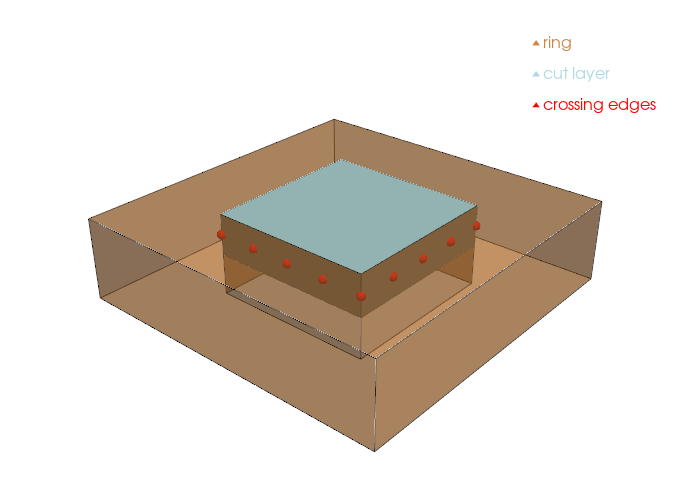

In [2]:
solver = new_solver("ring_3D_tphi", "look.log")
grid = solver.model.mesh
xyz = meshes.points(grid)
layer_cells = np.flatnonzero(meshes.array_values(grid, "TYPE", "elem") == 3)
mids, start, end = tree_gauge.edges(grid, layer_cells)
crossing = ~np.isclose(xyz[start, 2], xyz[end, 2])
print(f"{len(layer_cells)} layer cells, {len(mids)} edges: {crossing.sum()} crossing, {(~crossing).sum()} planar")
print("crossing edges oriented along +z:", bool(np.all(xyz[end[crossing], 2] > xyz[start[crossing], 2])))

g = pv.wrap(grid)
p = pv.Plotter(window_size=(700, 500))
for t, color, label, opacity in ((2, "peru", "ring", 0.5), (3, "lightblue", "cut layer", 1.0)):
    part = g.threshold((t, t), scalars="TYPE")
    p.add_mesh(part, color=color, opacity=opacity, label=label)
    p.add_mesh(part.extract_feature_edges(), color="black")
p.add_points(xyz[mids[crossing]], color="red", point_size=10, render_points_as_spheres=True, label="crossing edges")
p.add_legend(); p.camera_position = [(3.0, -3.5, 2.5), (0, 0, 0), (0, 0, 1)]; p.show()
with quietly():
    solver.close()

## One function, three drives

`ring(drive)` sets the model up as the example does, then runs 30 backward Euler steps of 10 ms:

* gauges of T-phi: $\mathbf{n}\times\mathbf{T}=0$ on the ring surface (`_T` = 0 on its edges), `_PHI` = 0 at the
  nodes inside the ring (first-order $\phi$: its gradients are in the edge space of $\mathbf{T}$);
* the cut: `_T` = 0 on the planar edges; the crossing edges, those on the ring's inner surface included, are taken out
  of the $\mathbf{n}\times\mathbf{T}=0$ set; then
  * `"induced"`: the crossing edges coupled on **one DOF**, the ring current (CP id 1 on their midside nodes, ids 2
    and 3 on the corner nodes of the two faces: they give the solver the orientation of each crossing edge); a
    uniform field of 1 T along z switched on at t = 0, the total potential $\phi=-H_0z$ on the box;
  * `"current"`: `_T` = I0 = 10 kA on every crossing edge (all along +z), no coupling, no field;
  * `"voltage"`: the coupling of `"induced"` and `VLTG` = V0 on one crossing midside node: the voltage around the
    ring, no field;
  * `"none"`: the field of `"induced"`, but **no cut**: the layer is air (TYPE 1).

Every value is set as in the example macros: select the points (or cells), then `set_value_on_selection`, with one
value for all or one value per selected id in increasing id order (e.g. the potential of each box point). It returns
the ring current from the cell values of `Jt` across a section of the ring, and the Joule power $\int\rho J^2$.

In [3]:
RHO, DT, STEPS = 1e-6, 0.01, 30

def ring(drive, b0=1.0, i0=1e4, v0=0.24):
    solver = new_solver("ring_3D_tphi", f"ring_{drive}.log")
    grid = solver.model.mesh
    xyz = meshes.points(grid)
    types = meshes.array_values(grid, "TYPE", "elem")
    if drive == "none":
        selection.select(grid, "TYPE", 3, location="elem")
        selection.set_value_on_selection(grid, "TYPE", 1, location="elem")      # the layer becomes air
    select_surface(grid, 2, [1, 3], midside=True)
    selection.set_value_on_selection(grid, "_T", 0.0, 2)           # n x T = 0 on the ring surface
    select_inside(grid, 2, [1, 3])
    selection.set_value_on_selection(grid, "_PHI", 0.0)            # PHI = 0 inside the ring
    if drive != "none":
        selection.select(grid, "TYPE", 3, location="elem")
        mids, start, end = tree_gauge.edges(grid, selection.selected_ids(grid, "elem"))
        cross = ~np.isclose(xyz[start, 2], xyz[end, 2])
        selection.select(grid, "ID", mids[~cross])
        selection.set_value_on_selection(grid, "_T", 0.0, 2)       # planar edges
        selection.select(grid, "ID", mids[cross])                  # crossing edges: imposed, or free and coupled
        selection.set_value_on_selection(grid, "_T", i0 if drive == "current" else np.nan, 2)
        if drive in ("induced", "voltage"):
            selection.set_value_on_selection(grid, "CP_0", 1)
            corners = np.unique(np.concatenate((start, end)))
            for face, z in ((2, 0.0), (3, 0.25)):                  # the faces c = 0 and c = 1 of the layer
                selection.select(grid, "ID", corners[np.isclose(xyz[corners, 2], z)])
                selection.set_value_on_selection(grid, "CP_0", face)
            solver.model.add_dof_couplings({1: ["T"], 2: ["T"], 3: ["T"]})
        if drive == "voltage":
            selection.select(grid, "ID", int(mids[cross][0]))
            selection.set_value_on_selection(grid, "VLTG", v0)
    selection.select_all(grid); selection.nsel_ext(grid)
    box = selection.selected_ids(grid, "node")
    field = b0 if drive in ("induced", "none") else 0.0
    selection.set_value_on_selection(grid, "_PHI", -field / MU0 * xyz[box, 2])   # one value per box point
    with quietly():
        solver.load_model_into_solver()
    solver.time_step["theta"] = 1.0
    c, vol = meshes.cell_centroids(grid), meshes.cell_sizes(grid)
    section = (types == 2) & (c[:, 0] > 0) & (c[:, 1] > 0) & (c[:, 1] < 0.25)
    rows = []
    for step in range(1, STEPS + 1):
        solver.time_step["time"] = step * DT
        with quietly():
            solver.solve()
        j = meshes.array_values(grid, "Jt", "elem")
        rows.append((step * DT, j[section, 1].sum() * 0.25 * 0.25, RHO * (np.einsum("ij,ij->i", j, j) @ vol)))
        if step == 1:
            first = pv.wrap(grid).copy()                          # the field of the first step
    out = {"t": np.array([r[0] for r in rows]), "I": np.array([r[1] for r in rows]),
           "P": np.array([r[2] for r in rows]), "grid": first}
    with quietly():
        solver.close()
    return out

runs = {d: ring(d) for d in ("induced", "current", "voltage", "none")}

## Resistance and time constant, three ways

* `"current"`: the current is imposed; once the transient eddy currents inside the ring section have died out, the
  power gives the resistance, $R=P/I_0^2$;
* `"voltage"`: the current rises to $V_0/R$ with the time constant $\tau=L/R$; with backward Euler,
  $I_k-I_\infty\propto(1+\Delta t/\tau)^{-k}$;
* `"induced"`: the current jumps at the field step, then decays as $(1+\Delta t/\tau)^{-k}$.

The three must give one ring: the same R and the same $\tau$.

R from the imposed current      : 20.422 uOhm   (rho x mean perimeter / section: 24.000)
voltage drive, I extrapolated   : 11.49 kA  (V0 / R = 11.75 kA)
tau from the voltage drive      : 75.8 ms
tau from the induced current    : 75.9 ms
L = tau R                       : 1.549 uH


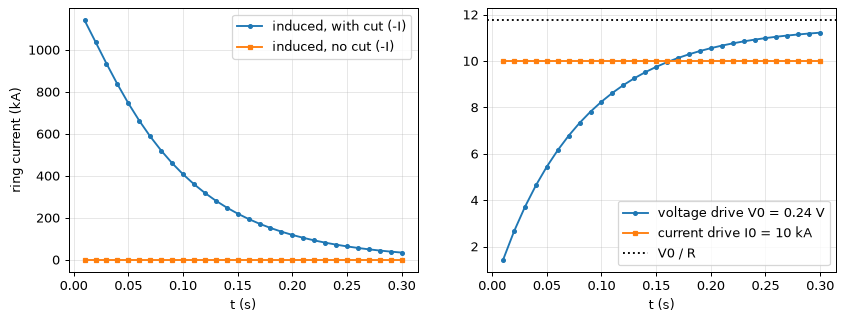

In [4]:
def tau_of(d):
    """tau from the step ratio of a backward-Euler exponential, d_{k+1} / d_k = 1 / (1 + dt / tau), steps 15 to 25."""
    ratio = (d[25] / d[15]) ** (1 / 10)
    return DT / (1.0 / ratio - 1.0)

r_current = runs["current"]["P"][-1] / 1e4**2
i_inf = 0.24 / r_current
iv = runs["voltage"]["I"]
tau_v = tau_of(np.diff(iv))                   # the increments of the rising current: no need of its final value
tau_i = tau_of(runs["induced"]["I"])
i_end = iv[-1] + np.diff(iv)[-1] / (DT / tau_v)   # the rising current extrapolated to t -> infinity
print(f"R from the imposed current      : {r_current * 1e6:.3f} uOhm   (rho x mean perimeter / section: {1e-6 * 6 / 0.25 * 1e6:.3f})")
print(f"voltage drive, I extrapolated   : {i_end / 1e3:.2f} kA  (V0 / R = {i_inf / 1e3:.2f} kA)")
print(f"tau from the voltage drive      : {tau_v * 1e3:.1f} ms")
print(f"tau from the induced current    : {tau_i * 1e3:.1f} ms")
print(f"L = tau R                       : {tau_i * r_current * 1e6:.3f} uH")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(runs["induced"]["t"], -runs["induced"]["I"] / 1e3, "o-", ms=3, label="induced, with cut (-I)")
ax[0].plot(runs["none"]["t"], -runs["none"]["I"] / 1e3, "s-", ms=3, label="induced, no cut (-I)")
ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("ring current (kA)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(runs["voltage"]["t"], runs["voltage"]["I"] / 1e3, "o-", ms=3, label="voltage drive V0 = 0.24 V")
ax[1].plot(runs["current"]["t"], runs["current"]["I"] / 1e3, "s-", ms=3, label="current drive I0 = 10 kA")
ax[1].axhline(i_inf / 1e3, color="k", ls=":", label="V0 / R")
ax[1].set_xlabel("t (s)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.show()

The two time constants agree, and the voltage drive tends to $V_0/R$ with R from the current drive: the cut DOF is
the net current of the ring and the voltage load `VLTG` is the voltage around it (the discrete energy balance
$P=V_0I$ holds at steady state; the benchmark `ring_transport` checks it). The 2 % left is the estimate of R: the
power from the cell means of J, $\sum\rho\bar J^2V$, is a little below $\int\rho J^2$, so R is low and $V_0/R$ high. The section current of the current drive
is $I_0$ at every step: an imposed current through a cut is exact. R is a little below
$\rho\,\ell/S$ with the mean perimeter: the current takes the inner, shorter path at the corners.

**Without the cut**, the field step induces only local eddy loops inside the ring section, with no net current: the
section current is about zero, the ring does not shield its hole. The solver gives no warning: a model of a
multiply connected conductor without its cut is simply another physical problem (a ring cut open). Check the net
current wherever it matters.

The field of the first step (t = 10 ms), on the plane y = 0: with the cut the ring current shields the hole;
without it the field goes through the hole, only the ring section itself is shielded by its local eddy loops.

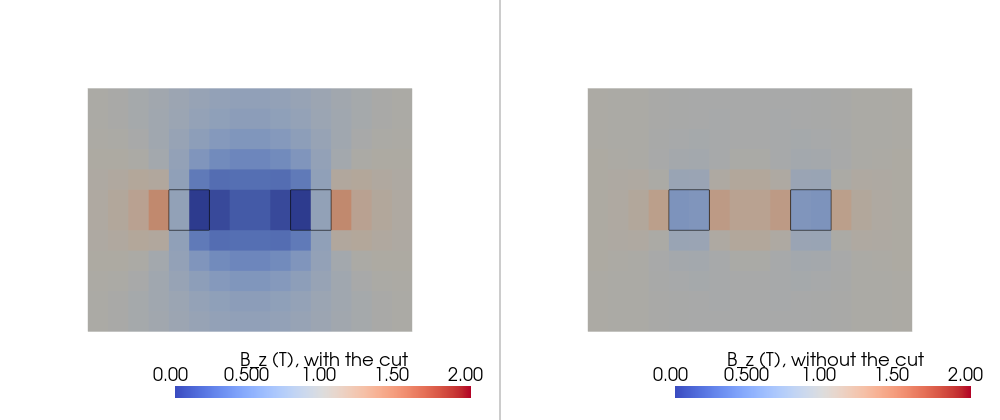

In [5]:
p = pv.Plotter(shape=(1, 2), window_size=(1000, 420))
for k, (name, title) in enumerate((("induced", "with the cut"), ("none", "without the cut"))):
    solver_grid = runs[name]["grid"]
    s = solver_grid.slice(normal="y", origin=(0, 0.01, 0))
    s.cell_data["B_z"] = s.cell_data["B"][:, 2]
    p.subplot(0, k)
    p.add_mesh(s, scalars="B_z", cmap="coolwarm", clim=(0.0, 2.0), scalar_bar_args={"title": f"B_z (T), {title}"})
    p.add_mesh(solver_grid.threshold((2, 2), scalars="TYPE").slice(normal="y", origin=(0, 0.01, 0)).extract_feature_edges(), color="black")
    p.view_xz()
p.show()

## A coil as T fixed on its edges

T-phi has no source current: a current-driven coil is $\mathbf{T}$ **fixed** on its edges. Take any $\mathbf{T}_0$
with $\nabla\times\mathbf{T}_0=\mathbf{J}$ (per ampere-turn) that is zero outside the winding and the hole it encloses,
and impose `_T` = $NI(t)\int_e\mathbf{T}_0\cdot d\mathbf{l}$ on every edge of those cells. For the square solenoid
a < max(|x|, |y|) < b, |z| < h:

$$\mathbf{T}_0=f\,\mathbf{e}_z,\qquad f=\begin{cases}J\,(b-\max(|x|,|y|)) & \text{winding}\\ J\,(b-a) & \text{hole column}
\\ 0 & \text{elsewhere}\end{cases}\qquad |z|<h .$$

The *hole column* is "the disk filling the hole": the region the winding encloses, over the height of the winding.
There $\mathbf{T}_0$ is uniform (no current), and $\mathbf{n}\times\mathbf{T}_0=0$ on the boundary of winding + hole.
A **conductor in the hole** (the core of the example) has its own $\mathbf{T}$, which cannot be fixed: $\mathbf{T}_0$ is
moved out of it by a gradient, $\mathbf{T}_0'=\mathbf{T}_0-\nabla g$, $g=J(b-a)\,z\,\chi$, $\chi$ = 1 on the nodes of the
core cells (exact on the edges). Below: the edge values of $\mathbf{T}_0'$ on the plane y = 0.

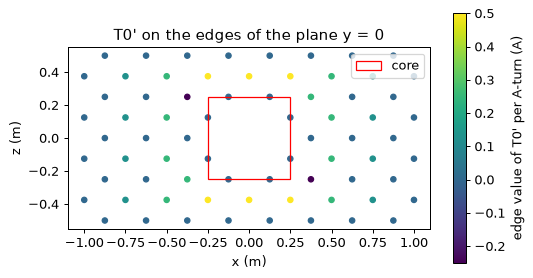

In [6]:
A_, B_, H_ = 0.5, 1.0, 0.5
J_UNIT = 1.0 / ((B_ - A_) * 2 * H_)

def t0(p):
    r = np.clip(np.maximum(np.abs(p[:, 0]), np.abs(p[:, 1])), A_, B_)
    return np.column_stack((np.zeros(len(p)), np.zeros(len(p)), J_UNIT * (B_ - r) * (np.abs(p[:, 2]) < H_)))

def coil_core(core=True, ni_max=5e5, t_ramp=0.1, dt=0.02, steps=15):
    """The solenoid ramped to ni_max over t_ramp; core False: the core cells are part of the hole (CUT_LAYER)."""
    solver = new_solver("coil_core_3D_tphi", f"coil_core_{core}.log")
    grid = solver.model.mesh
    xyz = meshes.points(grid)
    if not core:                                                   # the core cells become part of the hole
        selection.select(grid, "TYPE", 3, location="elem")
        selection.set_value_on_selection(grid, "TYPE", 4, location="elem")
        selection.set_value_on_selection(grid, "MATERIAL", 4, location="elem")
    types = meshes.array_values(grid, "TYPE", "elem")
    selection.select(grid, "TYPE", [2, 4], location="elem")
    mids, start, end = tree_gauge.edges(grid, selection.selected_ids(grid, "elem"))
    values = tree_gauge.edge_circulations(grid, start, end, t0)
    if core:
        selection.select(grid, "TYPE", 3, location="elem"); selection.nsle(grid)
        g = J_UNIT * (B_ - A_) * xyz[:, 2] * selection.selection_mask(grid, "node")   # chi: the core points
        values -= g[end] - g[start]
        select_inside(grid, 3, [1, 2, 4])
        selection.set_value_on_selection(grid, "_PHI", 0.0)
    selection.select_all(grid); selection.nsel_ext(grid)
    selection.select(grid, "ID", int(selection.selected_ids(grid)[0]))
    selection.set_value_on_selection(grid, "_PHI", 0.0)
    with quietly():
        solver.load_model_into_solver()
    solver.time_step["theta"] = 1.0
    c, vol = meshes.cell_centroids(grid), meshes.cell_sizes(grid)
    t0_cells = t0(c)
    centre = int(np.argmin(np.linalg.norm(xyz, axis=1)))
    rows = []
    for step in range(1, steps + 1):
        t = step * dt
        ni = ni_max * min(t / t_ramp, 1.0)
        selection.select(grid, "ID", mids)
        selection.set_value_on_selection(grid, "_T", ni * values, 2)
        solver.time_step["time"] = t
        with quietly():
            solver.solve()
        b = meshes.array_values(grid, "B", "elem")
        j = meshes.array_values(grid, "Jt", "elem")
        rows.append((t, ni, meshes.array_values(grid, "B", "node")[centre, 2],
                     float(np.einsum("ij,ij->i", t0_cells, b) @ vol),
                     np.linalg.norm(j[types == 3], axis=1).max() if core else 0.0))
    out = {k: np.array([r[i] for r in rows]) for i, k in enumerate(("t", "NI", "Bc", "Psi", "Jcore"))}
    out.update(mids=mids, values=values, xyz=xyz, grid=pv.wrap(grid).copy())
    with quietly():
        solver.close()
    return out

with_core, no_core = coil_core(True), coil_core(False)
m, v, x = with_core["mids"], with_core["values"], with_core["xyz"]
plane = np.isclose(x[m, 1], 0.0)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sc = ax.scatter(x[m[plane], 0], x[m[plane], 2], c=v[plane], cmap="viridis", s=18)
ax.add_patch(plt.Rectangle((-0.25, -0.25), 0.5, 0.5, fill=False, ec="red", label="core"))
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.legend(loc="upper right")
fig.colorbar(sc, label="edge value of T0' per A-turn (A)"); ax.set_title("T0' on the edges of the plane y = 0")
plt.show()

The vertical edges of the winding carry $J(b-r)\,\Delta z$, those of the hole column $J(b-a)\,\Delta z$ (0.25 per
ampere-turn here), the core edges zero, and the edges leaving the core carry the correction of the gradient (0.5 on
the vertical edges above and below the core, -0.25 on the horizontal ones at its corners): the flux of the hole is
routed around the core. The core keeps a free $\mathbf{T}$ (its eddy currents) with the usual gauges. The winding cells are
`SOLID_CONDUCTOR` (their $\mathbf{T}$ is fixed: no eddy current, their $\rho$ unused), the rest of the hole
`CUT_LAYER`.

The response to the ramp: without the core B at the centre follows the current; with it, the eddy currents of the
core delay the field there (the core's diffusion time $\mu_0\sigma c^2$ is about 0.08 s) and decay after the ramp.
The flux of a turn, $\Psi=\int\mathbf{T}_0\cdot\mathbf{B}\,dV$ per ampere-turn, gives the induced voltage of an
N-turn coil, $N\,d\Psi/dt$: T-phi has no voltage drive, the voltage comes afterwards from the flux.

no core         : Psi = 0.5126 Wb per turn at 500 kA-turns; N dPsi/dt during the ramp (N = 1000) 5126 V, after it 0.0 V
conducting core : Psi = 0.5126 Wb per turn at 500 kA-turns; N dPsi/dt during the ramp (N = 1000) 5125 V, after it 4.9 V


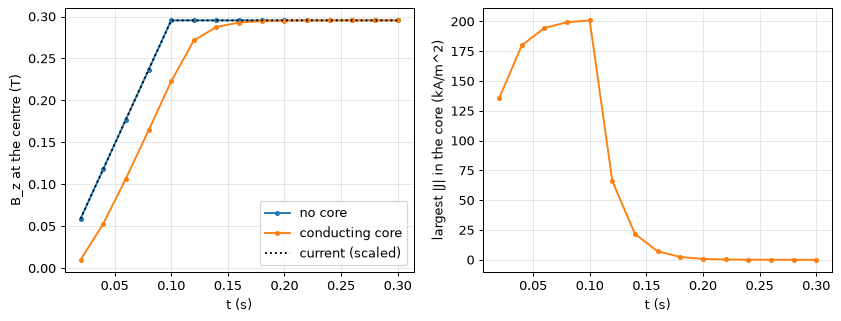

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for out, name in ((no_core, "no core"), (with_core, "conducting core")):
    ax[0].plot(out["t"], out["Bc"], "o-", ms=3, label=name)
ax[0].plot(with_core["t"], with_core["Bc"][-1] * with_core["NI"] / with_core["NI"][-1], "k:", label="current (scaled)")
ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("B_z at the centre (T)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(with_core["t"], with_core["Jcore"] / 1e3, "o-", ms=3, color="C1")
ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("largest |J| in the core (kA/m^2)"); ax[1].grid(alpha=0.3)
plt.show()
for out, name in ((no_core, "no core"), (with_core, "conducting core")):
    v = 1000 * np.diff(out["Psi"]) / np.diff(out["t"])
    print(f"{name:16s}: Psi = {out['Psi'][-1]:.4f} Wb per turn at 500 kA-turns; N dPsi/dt during the ramp "
          f"(N = 1000) {v[2]:.0f} V, after it {v[6]:.1f} V")

## Takeaways

* A conductor carrying a net current needs a cut: a one-cell `CUT_LAYER` layer, `_T` = 0 on its planar edges, the
  crossing edges (those on the conductor surface included) coupled (CP ids 1, 2, 3; induced), imposed (`_T` = I) or
  coupled and loaded by `VLTG` (voltage). Without it the solver silently models the conductor cut open.
* `tree_gauge.edges()` gives the edges of any cells in the solver's orientation; `tree_gauge.edge_circulations()`
  the edge values of a known field.
* A current-driven coil is `_T` = NI(t) x (edge values of T0) on the winding and the hole column; a conductor in the
  hole is cleared by a gradient; the induced voltage is N dPsi/dt afterwards.
* Several conductors: one cut each, one free cut DOF per hole; series and parallel connections: user manual, *Cuts*.